Les équations du mouvement du double pendule sont données par 

$$
\begin{align}
\ddot{\theta}_1 &= \frac{m_2 g \sin(\theta_2)\cos(\theta_1 - \theta_2) - m_2 \sin(\theta_1 - \theta_2)[\ell_1 \dot{\theta}_1^2 \cos(\theta_1 - \theta_2)+\ell_2 \dot{\theta}_2^2]-(m_1+m_2)g\sin(\theta_1)}{\ell_1[m_1 + m_2 \sin^2(\theta_1 - \theta_2)]}
\\
&= A

\\
\ddot{\theta}_2 &=\frac{(m_1 + m_2)[\ell_1 \dot{\theta}_1^2\sin(\theta_1 - \theta_2)- g\sin(\theta_2)+g\sin(\theta_1)\cos(\theta_1 - \theta_2)] + m_2\ell_2\dot{\theta}^2_2 \sin(\theta_1 - \theta_2) \cos(\theta_1 - \theta_2)}{\ell_2[m_1 + m_2 \sin^2(\theta_1 - \theta_2)]}
\\
&= B 
\end{align}
$$

On introduit les variables $z_1=\dot{\theta}_1$ et $z_2=\dot{\theta}_2$ tels que le système d'équations à résoudre soit le suivant,  
$$
\begin{align}
\begin{pmatrix}
\dot{\theta}_1
\\
\dot{\theta}_2
\\
\dot{z}_1
\\
\dot{z}_2
\end{pmatrix}
= \begin{pmatrix}
 z_1 \\
z_2 \\
 A(\theta_1, \theta_2, z_1, z_2) \\
B(\theta_1, \theta_2, z_1, z_2)
\end{pmatrix}
\end{align}
$$

Commençons par faire la fonction qui calcule $A$. 
$$
A = \frac{m_2 g \sin(\theta_2)\cos(\theta_1 - \theta_2) - m_2 \sin(\theta_1 - \theta_2)[\ell_1 z_1^2 \cos(\theta_1 - \theta_2)+\ell_2 z_2^2]-(m_1+m_2)g\sin(\theta_1)}{\ell_1[m_1 + m_2 \sin^2(\theta_1 - \theta_2)]}
$$

In [ ]:
import numpy as np
m1 = 1
m2 = 1
l1 = 0.5
l2 = 0.5
g = 9.81 

def compute_A(theta1, theta2, z1, z2):
    cos_term = np.cos(theta1 - theta2)
    sin_term = np.sin(theta1 - theta2)

    num = (m2 * g * np.sin(theta2) * cos_term 
           - m2 * sin_term * (l1 * z1 ** 2 * cos_term + l2 * z2 ** 2) 
           - (m1 + m2) * g * np.sin(theta1)
    )
    den = l1 * (m1 + m2 * sin_term ** 2)
    return num / den

On fait la même chose pour la fonction $B$.

$$
B =\frac{(m_1 + m_2)[\ell_1 z_1^2\sin(\theta_1 - \theta_2)- g\sin(\theta_2)+g\sin(\theta_1)\cos(\theta_1 - \theta_2)] + m_2\ell_2z^2_2 \sin(\theta_1 - \theta_2) \cos(\theta_1 - \theta_2)}{\ell_2[m_1 + m_2 \sin^2(\theta_1 - \theta_2)]}

$$

In [2]:
def compute_B(theta1, theta2, z1, z2):
    cos_term = np.cos(theta1 - theta2)
    sin_term = np.sin(theta1 - theta2)

    a = (m1 + m2) * (l1 * z1 ** 2 * sin_term - g * np.sin(theta2) +  g * np.sin(theta1) * cos_term )
    b = m2 * l2 * z2 ** 2 * sin_term * cos_term 
    num = a + b 
    den = l2 * (m1 + m2 * sin_term ** 2)
    return num / den

In [33]:
import numpy as np 
from scipy.integrate import solve_ivp

def double_pendulum(t, X):
    """
    Pendulum equations
    """
    theta1, theta2, z1, z2 = X
    A = compute_A(theta1, theta2, z1, z2)
    B = compute_B(theta1, theta2, z1, z2)
    return z1, z2, A, B

# Initial conditions
theta1_0, theta2_0, z1_0, z2_0 = np.pi/2, np.pi/4, 0, 0

# Simulation time
tmax = 10

# Solving with solve_ivp
soln = solve_ivp(double_pendulum, (0, tmax), (theta1_0, theta2_0, z1_0, z2_0 ), dense_output = True)

t = np.linspace(0, tmax, 10_000)
theta1, theta2, z1, z2 = soln.sol(t)

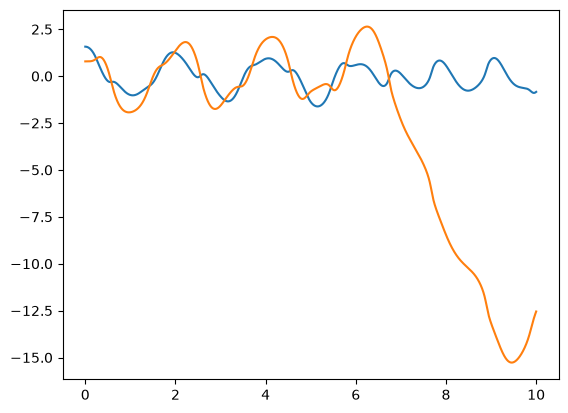

In [34]:
import matplotlib.pyplot as plt 

plt.plot(t, theta1)
plt.plot(t, theta2)

Maintenant, l'objectif est de créer une animation du mouvement du double pendule.

In [35]:
# Importing function for animation
from matplotlib.animation import FuncAnimation 

# Importing function for displaying the animation
from IPython.display import HTML, display



# Initial position of pendulums
x1 = l1 * np.sin(theta1_0)
y1 = -l1 * np.cos(theta1_0)
coords_pend1 = (x1, y1)


x2 = x1 + l2 * np.sin(theta2_0)
y2 = y1 - l2 * np.cos(theta2_0)
coords_pend2 = (x2, y2)


fig, axs = plt.subplots(1, 1, figsize = (5, 5))

axs.set_xlim([-1, 1])
axs.set_ylim([-1, 1])

(line1,) = axs.plot([0, x1], [0, y1], color = "k", lw = 3)
mass1 = axs.add_patch(
            plt.Circle(coords_pend1, 0.05, fc="deepskyblue", zorder=3)
        )

(line2,) = axs.plot([x1, x2], [y1, y2], color = "k", lw = "3")
mass2 = axs.add_patch(
            plt.Circle(coords_pend2, 0.05, fc="deepskyblue", zorder=3)
        )

def animate(frame):
    # Updating first pendulum position
    x1 = l1 * np.sin(theta1[frame])
    y1 = -l1 * np.cos(theta1[frame])

    new_coords1 = (x1, y1)

    mass1.set_center(new_coords1)
    line1.set_data([0, new_coords1[0]], [0, new_coords1[1]])

    x2 = x1 + l2 * np.sin(theta2[frame])
    y2 = y1 - l2 * np.cos(theta2[frame])
    new_coords2 = (x2, y2)
    mass2.set_center(new_coords2)
    line2.set_data([x1, x2], [y1, y2])

# Choosing the number of frames per second in the animation (e.g. 60)
fps = 60
delta_t = t[1]-t[0]

# Subsampling steps of simulation to simulate 60 frames per second
num_frames_per_sim_step = fps * delta_t
num_sim_step_per_frame = round(1 / (num_frames_per_sim_step))
frames = range(0, len(theta1), num_sim_step_per_frame)
interval = 1000 / fps # interval in ms 

ani = FuncAnimation(fig, animate, frames = frames, interval = interval, repeat = True)
plt.close(fig)

# Displaying the animation
display(HTML(ani.to_jshtml()))

Ajoutons maintenant un deuxième pendule aux conditions initiales proches mais légèrement différentes de celles du premier pendule.